# 1 · Multi-armed bandits for sector rotation
A bandit policy repeatedly picks one of *k* options, observes only the reward of the option it picked, and must balance **exploring** options it knows little about against **exploiting** the one that looks best so far. Asset selection looks like a bandit problem: each week, choose a sector to hold.

The notebook first checks the policies on a simulated problem where the answer is known, then runs them on 27 years of weekly returns of the nine original S&P 500 sector ETFs. Every decision uses only past data, a 10 bp cost is charged on turnover, and the results are compared with simple benchmarks, including a plain momentum rule.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = ROOT / "images"; DATA = ROOT / "data"
from rlfin import bandits
rng = np.random.default_rng(0)

## Sanity check: a stationary problem with a known answer
Five arms with Gaussian rewards (means 0, 0.1, 0.2, 0.3, 0.5; noise 1). Regret is the reward lost against always pulling the best arm; a good policy's cumulative regret flattens out.

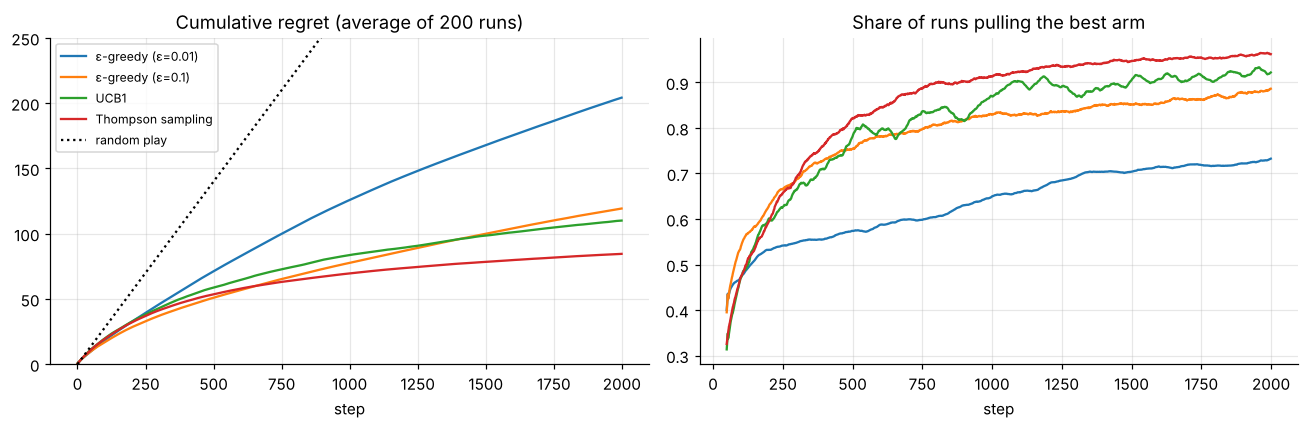

,"regret after 2,000 steps","best arm, last 200 steps %"
ε-greedy (ε=0.01),204.2,72.4
ε-greedy (ε=0.1),119.3,87.7
UCB1,110.1,92.3
Thompson sampling,84.6,96.0


In [2]:
means = [0.0, 0.1, 0.2, 0.3, 0.5]
pols = {"ε-greedy (ε=0.01)": lambda k, r: bandits.EpsilonGreedy(k, 0.01, r), "ε-greedy (ε=0.1)": lambda k, r: bandits.EpsilonGreedy(k, 0.1, r),
        "UCB1": lambda k, r: bandits.UCB1(k, 1.0, r), "Thompson sampling": lambda k, r: bandits.GaussianThompson(k, 1.0, 1.0, r)}
sim = {n: bandits.simulate_stationary(f, means, horizon=2000, runs=200) for n, f in pols.items()}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, (reg, opt) in sim.items():
    ax[0].plot(reg, label=n); ax[1].plot(pd.Series(opt).rolling(50).mean(), label=n)
ax[0].plot(np.arange(2000) * np.mean(np.max(means) - np.array(means)), "k:", label="random play")
ax[0].set_title("Cumulative regret (average of 200 runs)"); ax[0].set_xlabel("step"); ax[0].set_ylim(0, 250); ax[0].legend(fontsize=8)
ax[1].set_title("Share of runs pulling the best arm"); ax[1].set_xlabel("step")
plt.tight_layout(); plt.savefig(IMG / "bandit_regret.png", bbox_inches="tight"); plt.show()
pd.DataFrame({n: {"regret after 2,000 steps": reg[-1], "best arm, last 200 steps %": 100 * opt[-200:].mean()} for n, (reg, opt) in sim.items()}).T.round(1)

## Sector rotation, 1999-2026
Weekly (Friday-to-Friday) returns of XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV and XLY. The reward of a pick is that sector's return in the following week. Exploration bonuses are scaled to the size of weekly returns (about 3%).

In [3]:
px = pd.read_csv(DATA / "sector_etfs.csv", index_col=0, parse_dates=True)
wk = px.resample("W-FRI").last().pct_change().dropna()
sectors = [c for c in wk.columns if c != "SPY"]
R = wk[sectors]; spy = wk["SPY"]
COST = 0.001
print(f"{len(R)} weeks, {R.index[0]:%d %b %Y} to {R.index[-1]:%d %b %Y}; weekly return s.d. {R.std().mean():.3f}")
k = len(sectors); s = R.std().mean()

def run(make, seeds=1, **kw):
    outs = [bandits.backtest(R, make(np.random.default_rng(i)), cost=COST, **kw) for i in range(seeds)]
    ret = pd.concat([o["ret"] for o in outs], axis=1).mean(1)
    return ret, outs[0], np.mean([o["turnover"].mean() for o in outs])

def fixed(weights_fn):
    w_prev = np.zeros(k); rets = []; tos = []
    for t in range(len(R)):
        w = weights_fn(t); to = np.abs(w - w_prev).sum(); r = R.iloc[t].to_numpy()
        rets.append(w @ r - COST * to); tos.append(to); w_prev = w * (1 + r) / (1 + w @ r)
    return pd.Series(rets, R.index), None, np.mean(tos)

def momentum(t, look=12):
    w = np.zeros(k)
    if t < look: w[:] = 1 / k
    else: w[np.argmax((1 + R.iloc[t - look:t]).prod().to_numpy())] = 1
    return w

res = {
    "ε-greedy (ε=0.1), 50 seeds": run(lambda g: bandits.EpsilonGreedy(k, 0.1, g), seeds=50),
    "UCB1": run(lambda g: bandits.UCB1(k, s, g)),
    "Thompson sampling, 50 seeds": run(lambda g: bandits.GaussianThompson(k, s, 0.01, g), seeds=50),
    "discounted UCB (γ=0.95)": run(lambda g: bandits.DiscountedUCB(k, 0.95, s, g)),
    "risk-aware: ½ disc. UCB + ½ min-variance": run(lambda g: bandits.DiscountedUCB(k, 0.95, s, g), blend=0.5),
    "momentum: last 12 weeks' best sector": fixed(momentum),
    "equal weight (weekly rebalanced)": fixed(lambda t: np.full(k, 1 / k)),
    "random sector each week, 50 seeds": (pd.concat([pd.Series([R.iloc[t, g.integers(k)] for t in range(len(R))], R.index) for g in [np.random.default_rng(100 + i) for i in range(50)]], axis=1).mean(1) - COST * (1 - 1 / k) * 2, None, 2 * (1 - 1 / k)),
    "SPY buy and hold": (spy, None, 0.0),
}
def summary(r, to):
    lr = np.log1p(r); ann = np.exp(lr.mean() * 52) - 1; vol = r.std() * np.sqrt(52); w = (1 + r).cumprod()
    return {"ann. return %": 100 * ann, "ann. vol %": 100 * vol, "Sharpe (rf=0)": r.mean() * 52 / vol,
            "max drawdown %": 100 * (w / w.cummax() - 1).min(), "weekly turnover": to}
tab = pd.DataFrame({n: summary(r, to) for n, (r, _, to) in res.items()}).T
tab.round(2)

1451 weeks, 15 Jan 1999 to 30 Oct 2026; weekly return s.d. 0.030


,ann. return %,ann. vol %,Sharpe (rf=0),max drawdown %,weekly turnover
"ε-greedy (ε=0.1), 50 seeds",6.74,17.44,0.46,-52.04,0.38
UCB1,2.91,22.79,0.24,-78.43,0.41
"Thompson sampling, 50 seeds",0.91,17.15,0.14,-68.46,1.51
discounted UCB (γ=0.95),0.62,21.05,0.13,-76.12,1.73
risk-aware: ½ disc. UCB + ½ min-variance,4.30,16.57,0.34,-55.15,0.91
momentum: last 12 weeks' best sector,2.94,21.66,0.24,-56.69,0.63
equal weight (weekly rebalanced),9.10,17.03,0.60,-52.56,0.01
"random sector each week, 50 seeds",-0.41,17.08,0.06,-67.24,1.78
SPY buy and hold,8.43,17.69,0.55,-54.61,0.00


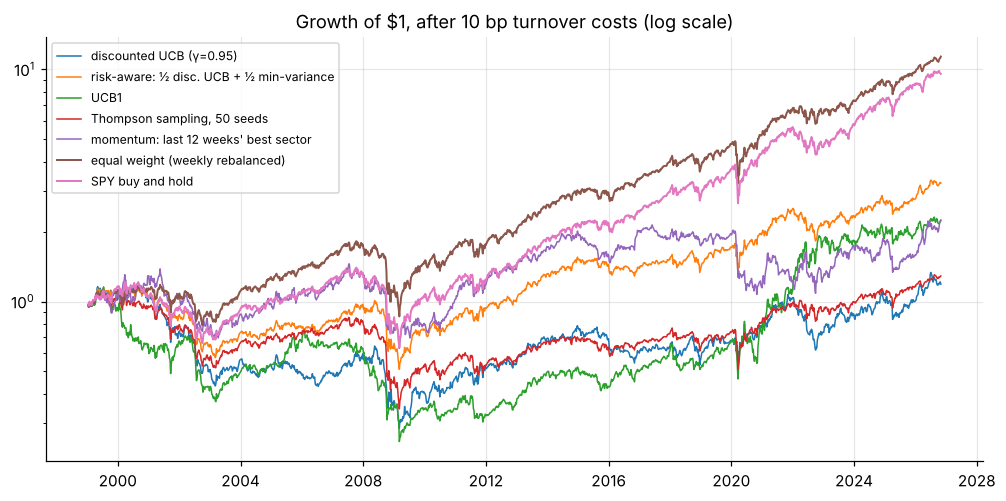

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
for n in ["discounted UCB (γ=0.95)", "risk-aware: ½ disc. UCB + ½ min-variance", "UCB1", "Thompson sampling, 50 seeds", "momentum: last 12 weeks' best sector", "equal weight (weekly rebalanced)", "SPY buy and hold"]:
    ax.plot((1 + res[n][0]).cumprod(), label=n, lw=1.3 if "SPY" in n or "equal" in n else 1)
ax.set_yscale("log"); ax.set_title("Growth of \\$1, after 10 bp turnover costs (log scale)"); ax.legend(fontsize=8)
plt.savefig(IMG / "sector_bandits_wealth.png", bbox_inches="tight"); plt.show()

### Which sectors does each policy hold, and when?

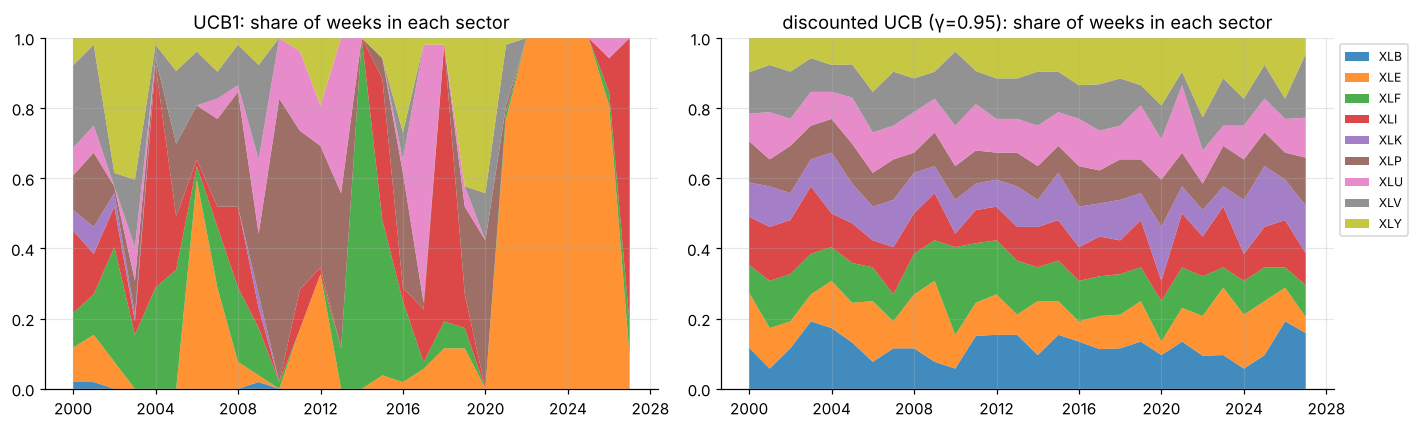

UCB1 share of all weeks by sector, %: {'XLE': 28.0, 'XLP': 16.9, 'XLI': 14.5, 'XLF': 14.3, 'XLY': 9.7, 'XLU': 8.6, 'XLV': 7.0, 'XLK': 0.8, 'XLB': 0.2}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, n in zip(ax, ["UCB1", "discounted UCB (γ=0.95)"]):
    picks = res[n][1]["arm"]
    share = pd.get_dummies(picks).reindex(columns=sectors, fill_value=0).astype(float).resample("YE").mean()
    a.stackplot(share.index, share.T.to_numpy(), labels=sectors, alpha=0.85)
    a.set_title(f"{n}: share of weeks in each sector"); a.set_ylim(0, 1)
ax[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "sector_bandits_picks.png", bbox_inches="tight"); plt.show()
print("UCB1 share of all weeks by sector, %:", (100 * res["UCB1"][1]["arm"].value_counts(normalize=True)).round(1).to_dict())

### Does the result hold in both halves of the sample?

In [6]:
halves = {"1999-2012": slice("1999", "2012"), "2013-2026": slice("2013", "2026")}
sub = pd.DataFrame({h: {n: summary(r[sl], to)["Sharpe (rf=0)"] for n, (r, _, to) in res.items()} for h, sl in halves.items()})
sub.round(2)

,1999-2012,2013-2026
"ε-greedy (ε=0.1), 50 seeds",0.18,0.81
UCB1,-0.22,0.67
"Thompson sampling, 50 seeds",-0.13,0.47
discounted UCB (γ=0.95),-0.08,0.39
risk-aware: ½ disc. UCB + ½ min-variance,0.09,0.63
momentum: last 12 weeks' best sector,0.21,0.27
equal weight (weekly rebalanced),0.35,0.90
"random sector each week, 50 seeds",-0.13,0.31
SPY buy and hold,0.22,0.96


## Findings
* **The policies behave as theory says when the problem is stationary.** On the simulated arms, Thompson sampling has the lowest regret (85 after 2,000 steps, best arm 96% of the time), then UCB1 (110) and ε-greedy with ε = 0.1 (119). Too little exploration (ε = 0.01) locks onto a wrong arm in many runs (regret 204).
* **None of them beats simple diversification on sectors.** Over 1,451 weeks (1999-2026), after 10 bp costs, the equal-weight sector portfolio earns 9.1% a year (Sharpe 0.60) and SPY 8.4% (0.55). The best bandit, ε-greedy averaged over 50 seeds, earns 6.7% (0.46), UCB1 2.9%, Thompson 0.9% and discounted UCB 0.6%. Picking a random sector each week loses 0.4%.
* **Costs explain much of the gap.** Discounted UCB and Thompson sampling change sector most weeks (turnover 1.5-1.7 a week), which costs about 8-9% a year at 10 bp. UCB1 trades far less (0.41) but concentrates: it held energy (XLE) in 28% of all weeks, including almost all of 2021-2026, and suffered a 78% drawdown.
* **Weekly sector returns are too noisy for a bandit to learn which sector is best.** With a weekly s.d. of about 3% and mean differences of a few basis points, the "forgetting" bandit never becomes confident and keeps spreading its picks across all nine sectors (see the stacked chart). Blending its pick with a minimum-variance portfolio (the risk-aware variant) halves turnover and lifts the Sharpe ratio from 0.13 to 0.34, but it still trails equal weight.
* **Result by half-sample:** equal weight beats every bandit in both 1999-2012 and 2013-2026. Note that a 50-seed average is itself a diversified portfolio, which flatters ε-greedy and Thompson sampling relative to a single run.
* **Use:** bandits fit problems with many repeated decisions and fairly stable payoffs, such as order routing, ad or offer selection, and choosing among execution algorithms. They are a poor fit for picking assets from weekly returns.